In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

## Visualizing K-Nearest Neighbors Regression Functions

A predictive model is simply a function $f$ that maps feature values ${\bf x}$ to target values $y$. We can visualize $f$ when ${\bf x}$ consists of just a single feature. We have seen that a linear regression function $f$ based on a single feature $x$ is a linear function of $x$. What does $f$ look like when the model is a $k$-nearest neighbors regressor?


### K-Nearest Neighbors Regression Functions for a Single Quantitative Feature: Wine Data


Recall the wines data set where our target is log(price), a proxy for quality.
We'll use a K-Nearest Neighbors model for predicting log(price) from a single feature, age.

First, we extract the training data. There is no need to scale the features in this case because there is only one feature. (The point of scaling is to bring all of the *feature* variables to the same scale before computing distances between observations.)

In [2]:
bordeaux_df = pd.read_csv("https://dlsun.github.io/pods/data/bordeaux.csv",
                          index_col="year")

# Split the data into training and test sets
bordeaux_train = bordeaux_df.loc[:1980].copy()
bordeaux_test = bordeaux_df.loc[1981:].copy()

# Log transform the target
bordeaux_train["log(price)"] = np.log(bordeaux_train["price"])

# train on a single feature, age
X_train = bordeaux_train[["age"]]
y_train = bordeaux_train["log(price)"]

In [3]:
bordeaux_train[["age", "log(price)"]].sort_values("age").head(5)

,age,log(price)
year,,
1980,12,2.639057
1979,13,3.044522
1978,14,3.295837
1977,15,2.397895
1976,16,3.218876


Let's make a scatterplot of the training data. Careful! In the reading, we made several scatterplots where both the x-axis and y-axis corresponded to *feature* variables (and the target corresponded to color). But now the x-axis is the feature and the y-axis is the target.

<Axes: xlabel='age', ylabel='log(price)'>

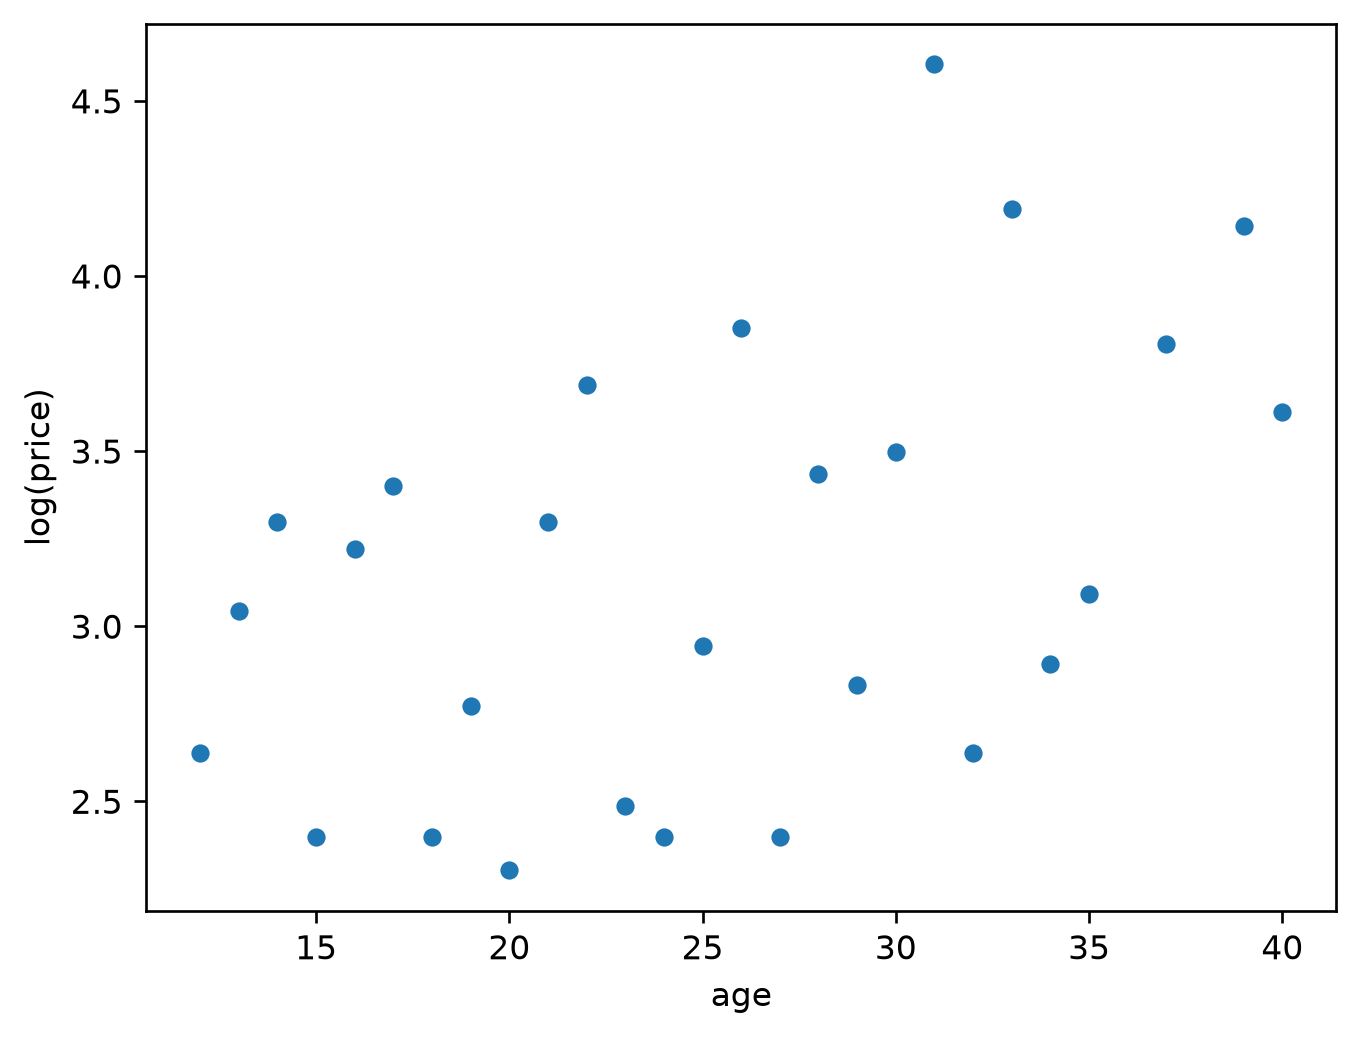

In [4]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

1. Consider a **1-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 13? age = 11.5? age = 12.49? age = 12.51? age = 13.49? age = 13.51?

**Sketch on paper and discuss with your partner.**

2. Consider a **2-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 12.99? age = 13.01? age = 13.99? age = 14.01?

**Sketch on paper and discuss with your partner.**

3. What would the 27-nearest neighbors regression function look like? **Discuss with your partner before proceeding.** Hint: what is special about 27 in this example?

**Sketch on paper and discuss with your partner.**

4. Now we'll fit a K-nearest neighbors regression model and plot the regression function for K=1, 2, 10, 27. The code below basically implements the code from the previous part for each of the values of K. Run the code and **discuss the output with your partner**. Do the regression functions look like what you expected? What happens as K increases?

<Axes: xlabel='age', ylabel='log(price)'>

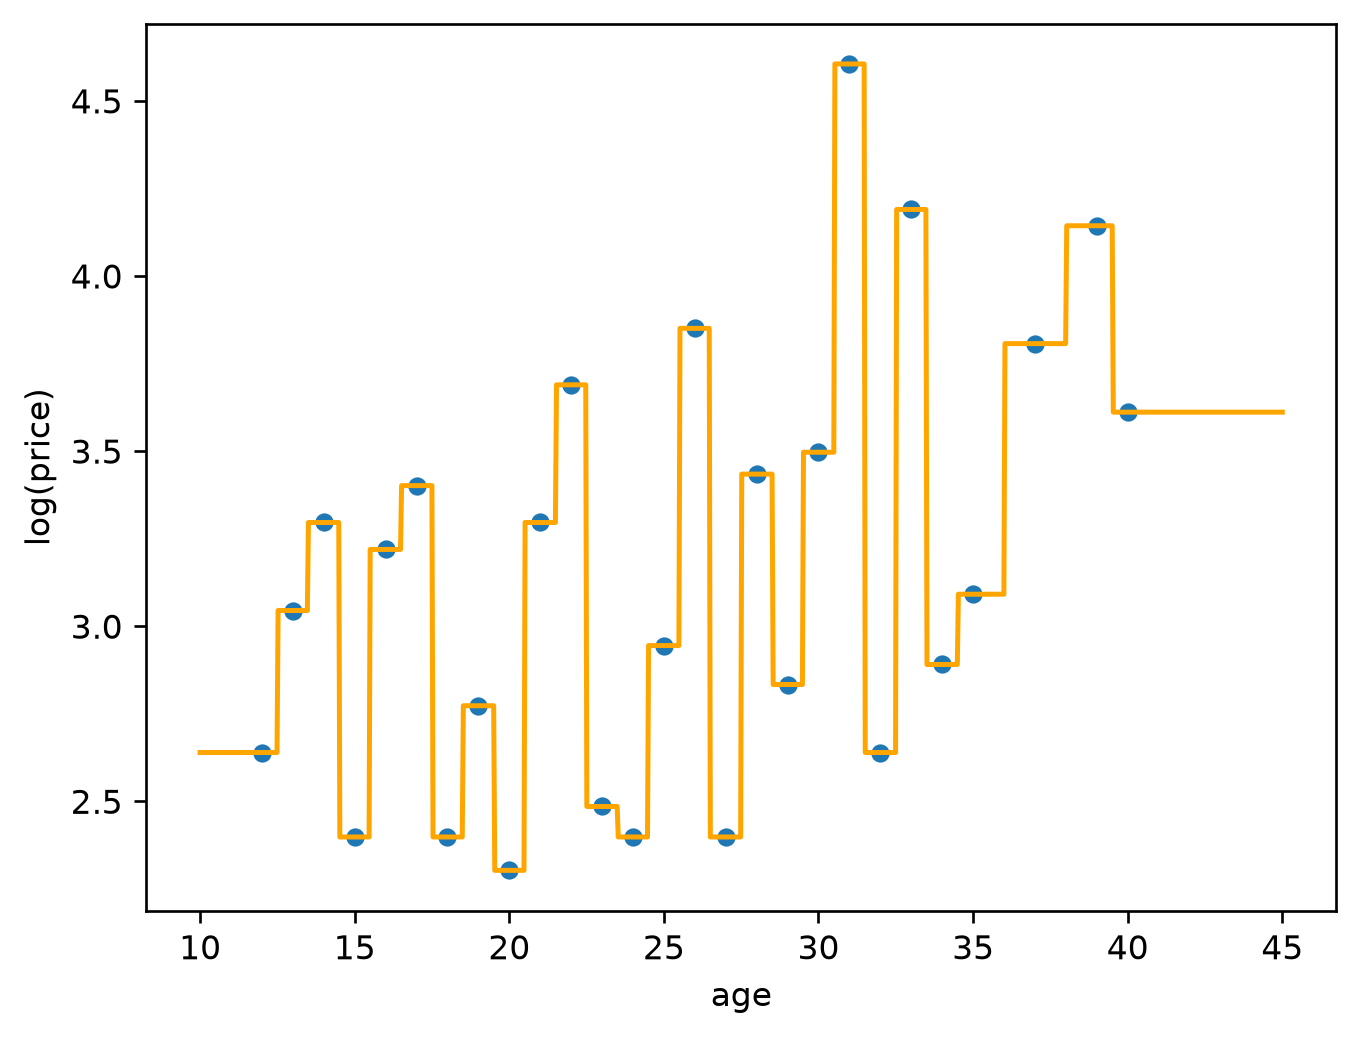

In [5]:
# 1-nearest neighbor model
from sklearn.neighbors import KNeighborsRegressor

# Fit k-nearest neighbors
model = KNeighborsRegressor(n_neighbors=1)
model.fit(X=X_train, y=y_train)

# Define a grid of feature values to make predictions for
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

# Make predictions at those feature values.
y_new_ = pd.Series(
    # ADD YOUR CODE HERE,
    model.predict(X_new),
    index=X_new["age"]
)

# Plot the scatter plot and the predictions (regression function)
bordeaux_train.plot.scatter(x="age", y="log(price)")
y_new_.plot.line(color = "orange")


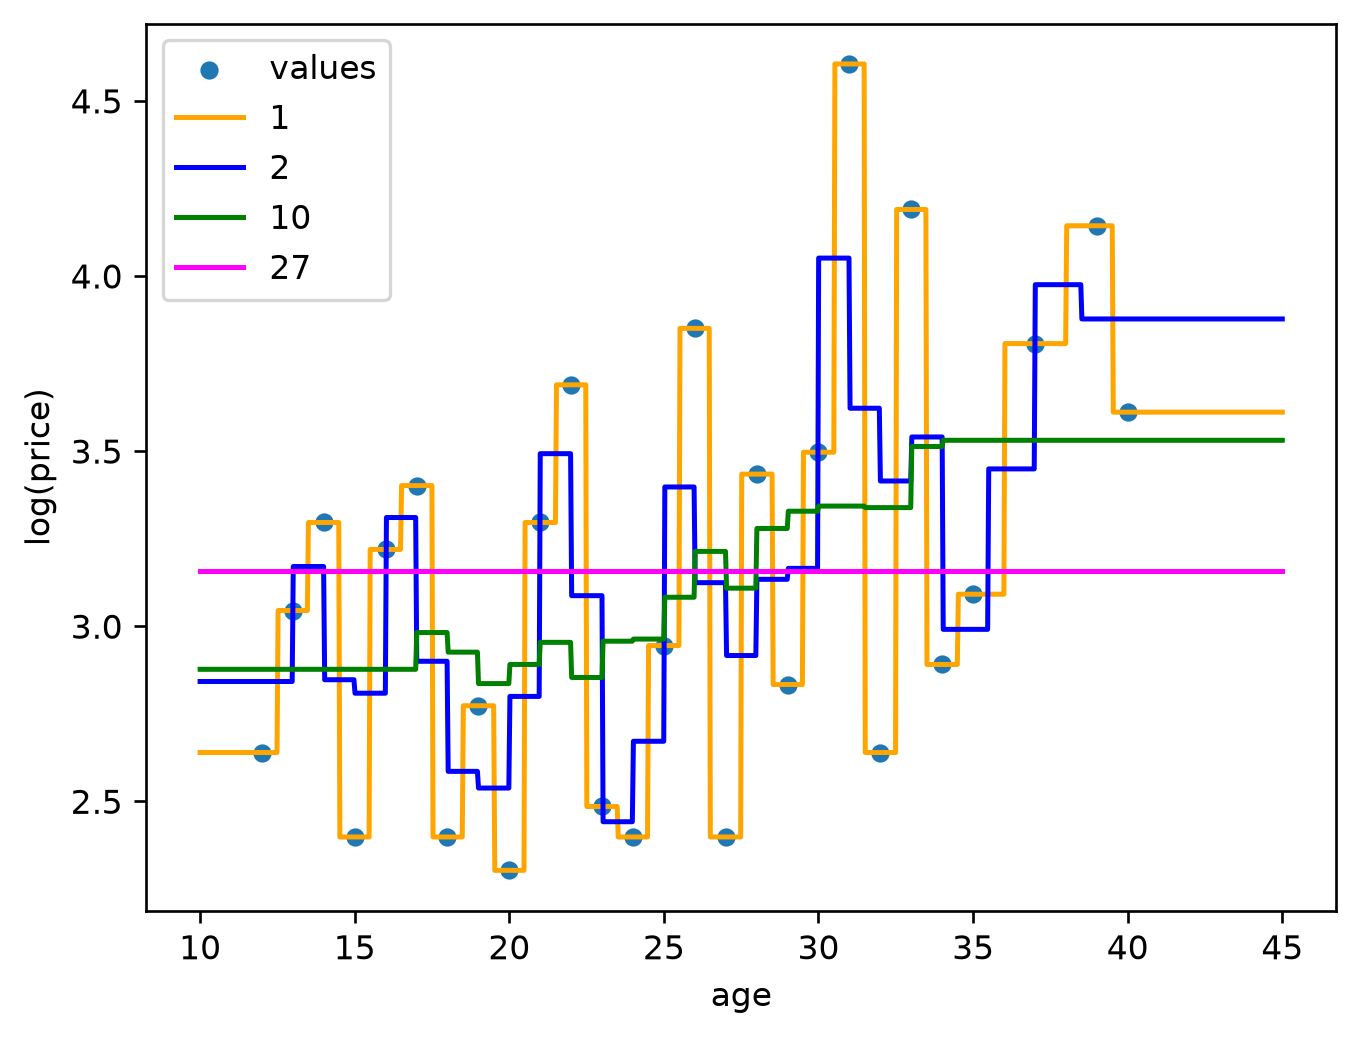

In [6]:
# k-nearest neighbors for several values of k
ks = [1, 2, 10, 27]
colors = ["orange", "blue", "green", "magenta", "black"]

bordeaux_train.plot.scatter(x="age", y="log(price)")

# Define a grid of feature values.
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

for i in range(len(ks)):

  # Fit k-nearest neighbors
  model = KNeighborsRegressor(n_neighbors=ks[i])
  model.fit(X=X_train, y=y_train)

  # Make predictions at those feature values.
  y_new_ = pd.Series(
      model.predict(X_new),
      index=X_new["age"]
  )

  # Plot the predictions.
  y_new_.plot.line(color = colors[i])
  plt.legend(["values"] + ks);


### K-Nearest Neighbors Regression Functions for a Single Categorical Feature: Housing Data

Recall the Ames housing data set. We'll use a single categorical feature---Neighborhood---to predict SalePrice.

In [7]:
df_ames = pd.read_csv("http://dlsun.github.io/pods/data/AmesHousing.txt", sep = "\t")

df_ames[["Neighborhood", "SalePrice"]]

,Neighborhood,SalePrice
0,NAmes,215000
1,NAmes,105000
2,NAmes,172000
3,NAmes,244000
4,Gilbert,189900
...,...,...
2925,Mitchel,142500
2926,Mitchel,131000
2927,Mitchel,132000
2928,Mitchel,170000


We'll fit a **10-nearest neighbors** regression model to predict house price using **Neighborhood** as the only feature. Since Neighborhood is categorical we first need to convert it to dummies, using a `ColumnTransformer` and a `Pipeline`.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

X = df_ames[["Neighborhood"]]
y = df_ames["SalePrice"]

ct = ColumnTransformer(
    [("dummify", OneHotEncoder(), ["Neighborhood"])]
)

knn_model = Pipeline([
    ("preprocessing", ct),
    ("knn", KNeighborsRegressor(n_neighbors=10))
])

knn_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['Neighborhood']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,ex

Now we'll find the predicted price for each Neighborhood.

In [9]:
neighborhoods = pd.Series(df_ames["Neighborhood"].unique(), name="Neighborhood").to_frame()
neighborhoods["predicted"] = knn_model.predict(neighborhoods)
neighborhoods

,Neighborhood,predicted
0,NAmes,142771.0
1,Gilbert,221722.5
2,StoneBr,300637.0
3,NWAmes,180795.0
4,Somerst,230960.0
5,BrDale,108850.0
6,NPkVill,140115.0
7,NridgHt,346588.3
8,Blmngtn,209917.9
9,NoRidge,325105.0


Let's compare the predicted prices to the mean price for each neighborhood.

In [10]:
pd.merge(pd.merge(neighborhoods,
                  df_ames.groupby("Neighborhood")["SalePrice"].mean(), left_on = "Neighborhood", right_index = True),
         df_ames["Neighborhood"].value_counts(), left_on = "Neighborhood", right_index = True).sort_values("count")

,Neighborhood,predicted,SalePrice,count
27,Landmrk,122920.0,137000.000000,1
26,GrnHill,150790.0,280000.000000,2
12,Greens,181175.0,193531.250000,8
21,Blueste,143590.0,143590.000000,10
6,NPkVill,140115.0,140710.869565,23
25,Veenker,254750.0,248314.583333,24
8,Blmngtn,209917.9,196661.678571,28
5,BrDale,108850.0,105608.333333,30
24,MeadowV,104390.0,95756.486486,37
16,ClearCr,222100.0,208662.090909,44


 5. For what neighborhood is the predicted price equal to the neighborhood's mean price? Why? What is special about that neighborhood? Can you explain why the predicted prices don't match the mean price for the other neighborhoods?

**Discuss with your partner.**

### K-Nearest Neighbors Regression Functions for Two Quantitative Features: Sketching for Small Training Data

When there are multiple features, a regression function will be a surface in a higher dimensional space and is therefore difficult to visualize. Essentially the regression function splits the feature space into regions based on which $K$ points in the training data are closest, and makes constant predictions over these regions so that the regression surface has something like a ["log step"](https://i.pinimg.com/originals/f3/61/21/f36121c84fa42b6cad525f865d61d049.png) shape.

We'll sketch plots of the regression surface when there are two quantitative features and the training data only contains a few observations. Assume that the features have already been scaled and that Euclidean distance is used to determine nearest neighbors.

6. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 2 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Sketch on paper and discuss with your partner.**

7. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Sketch on paper and discuss with your partner.**

8. Consider **2-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Sketch on paper and discuss with your partner.**

## Decision Trees

Back to the wine data. Suppose again that we want to predict log(price) based on just a single feature, age.

<Axes: xlabel='age', ylabel='log(price)'>

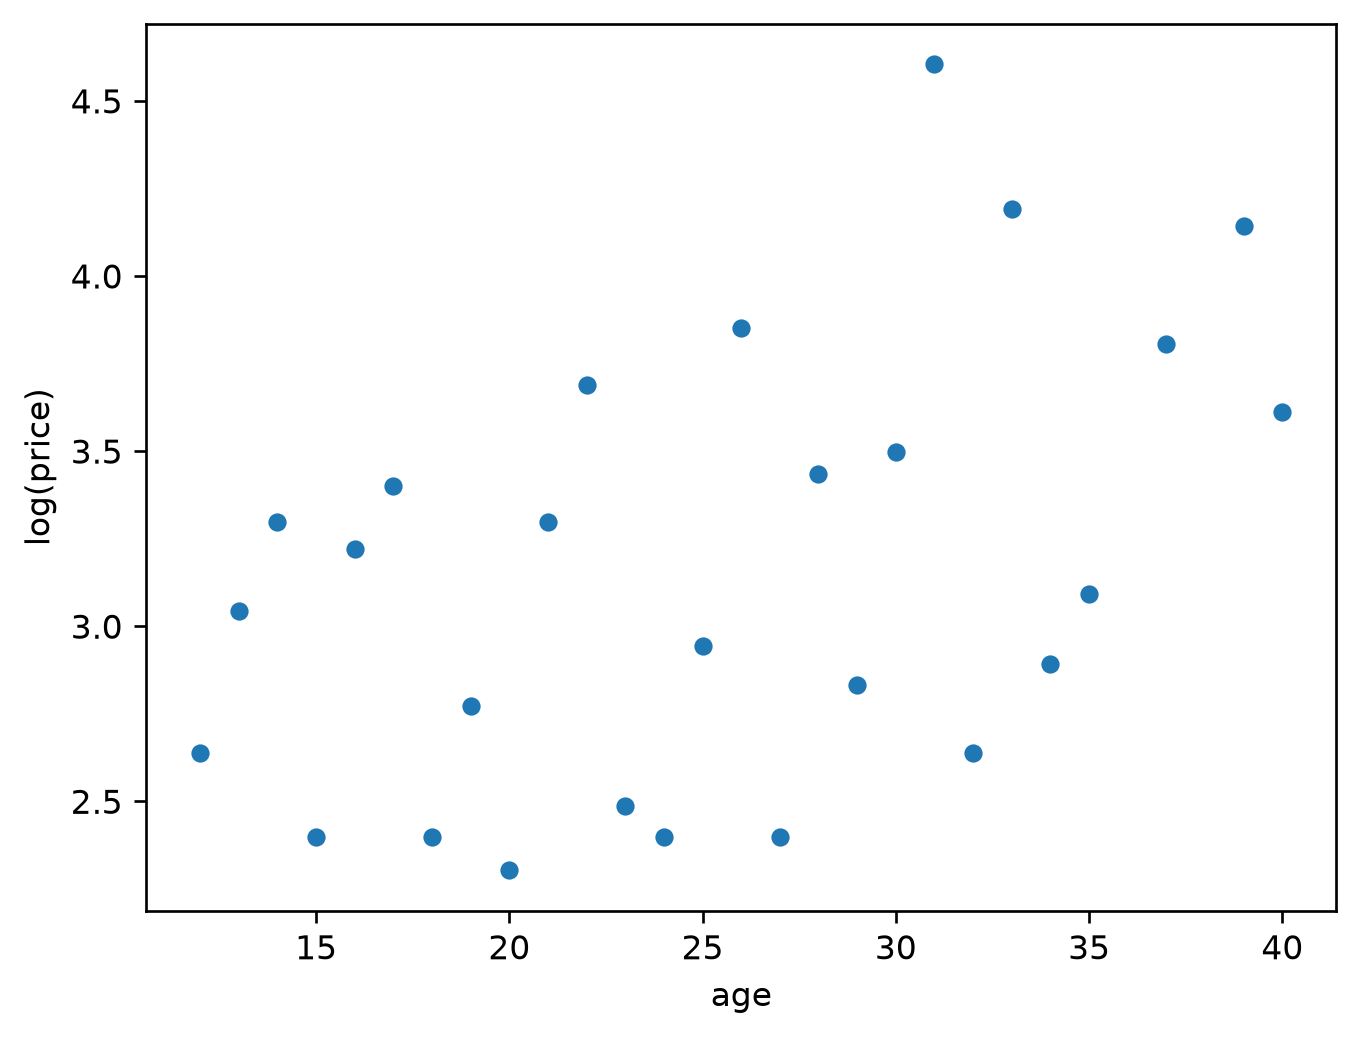

In [11]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

9. Suppose we use a regression decision tree with a single split at 20.5. Sketch a plot of what the regression function would look like.

**Sketch on paper and discuss with your partner.**

10. Suppose we use a decision tree with two splits at 20.5 and 30.5. Sketch a plot of what the regression function would look like.

**Sketch on paper and discuss with your partner.**

## Fitting KNN Regression Models with scikit-learn: Housing data

11. Fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Use a pipeline and column transformers as needed. Make a scatter plot of predicting price versus actual price.

In [12]:
import numpy as np
import pandas as pd

# Preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

# Pipeline
from sklearn.pipeline import Pipeline

# Data splitting, cross-validation, and tuning
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    train_test_split,
)

# Regression evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


In [13]:
# YOUR CODE HERE. ADD CELLS AS NEEDED

data_url = "https://dlsun.github.io/pods/data/AmesHousing.txt"

df_housing = pd.read_csv(
    data_url,
    sep="\t",
)

df_housing.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [14]:
target = "SalePrice"

numeric_features = [
    "Gr Liv Area",    # Above-ground living area in square feet
    "Bedroom AbvGr",  # Number of bedrooms above ground
    "Full Bath", 
    "Half Bath"     # Number of full bathrooms
]

categorical_features = [
    "Neighborhood"
]

all_features = numeric_features + categorical_features

data = df_housing[
    [target] + all_features
].copy()


print(data.shape)
data.head(100)

(2930, 6)


,SalePrice,Gr Liv Area,Bedroom AbvGr,Full Bath,Half Bath,Neighborhood
0,215000,1656,3,1,0,NAmes
1,105000,896,2,1,0,NAmes
2,172000,1329,3,1,1,NAmes
3,244000,2110,3,2,1,NAmes
4,189900,1629,3,2,1,Gilbert
...,...,...,...,...,...,...
95,155000,1200,2,2,1,Somerst
96,151000,1200,2,2,1,Somerst
97,149500,1200,2,2,1,Somerst
98,152000,1236,2,2,1,Somerst


In [15]:
X = data[all_features]
y = data[target]


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.10,  
    random_state=42,  
)


In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features,
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
            categorical_features,
        ),
    ],

    remainder="drop",
)


knn_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("knn",  KNeighborsRegressor(
            n_neighbors=10
        ),
),
    ]
)



In [18]:
knn_pipeline.fit(X_train, y_train)
predictions = knn_pipeline.predict(X_test)

In [19]:
import numpy as np
import pandas as pd
from plotnine import ggplot, aes, geom_point, geom_smooth, geom_line, labs, scale_x_continuous, theme_minimal, geom_abline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

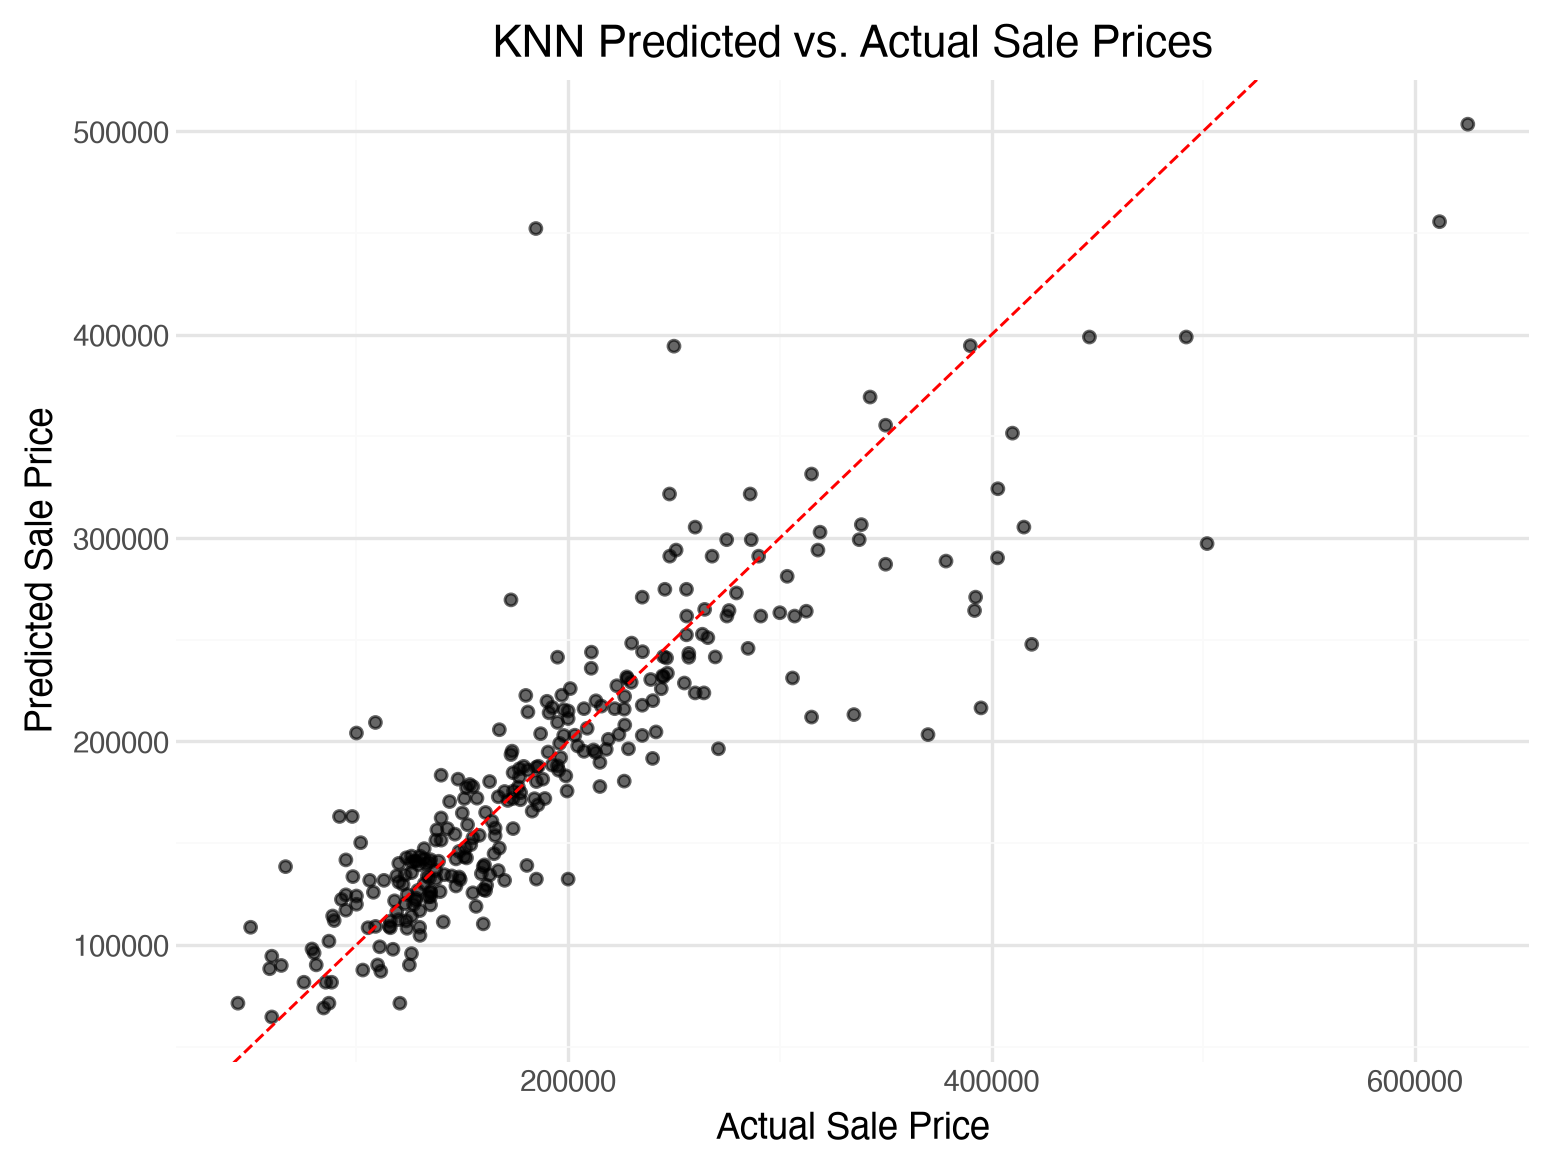

In [20]:
plot_data = pd.DataFrame({
    "actual_price": y_test.to_numpy(),
    "predicted_price": predictions
})

(
    ggplot(
        plot_data,
        aes(
            x="actual_price",
            y="predicted_price"
        )
    )
    + geom_point(alpha=0.6)
    + labs(
        x="Actual Sale Price",
        y="Predicted Sale Price",
        title="KNN Predicted vs. Actual Sale Prices"
    )
    + theme_minimal()
    + geom_abline(
    intercept=0,
    slope=1,
    color="red",
    linetype="dashed"
)
)

12. Repeat the previous part to fit a $k$-nearest neighbors model for some other value of $k$. Experiment with different values of $k$. (For this, you can just pick and choose a few, no need to automate it. We'll see how to do that later.) What value of $k$ seems to be "best"? How are you deciding?

In [21]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
target = "SalePrice"

numeric_features = [
    "Gr Liv Area",    # Above-ground living area in square feet
    "Bedroom AbvGr",  # Number of bedrooms above ground
    "Full Bath", 
    "Half Bath"     # Number of full bathrooms
]

categorical_features = [
    "Neighborhood"
]

all_features = numeric_features + categorical_features

data = df_housing[
    [target] + all_features
].copy()

X = data[all_features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.10,  
    random_state=42,  
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features,
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
            categorical_features,
        ),
    ],

    remainder="drop",
)


knn_5 = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("knn",  KNeighborsRegressor(
            n_neighbors=5
        ),
),
    ]
)

knn_5.fit(X_train, y_train)
predictions_5 = knn_5.predict(X_test)

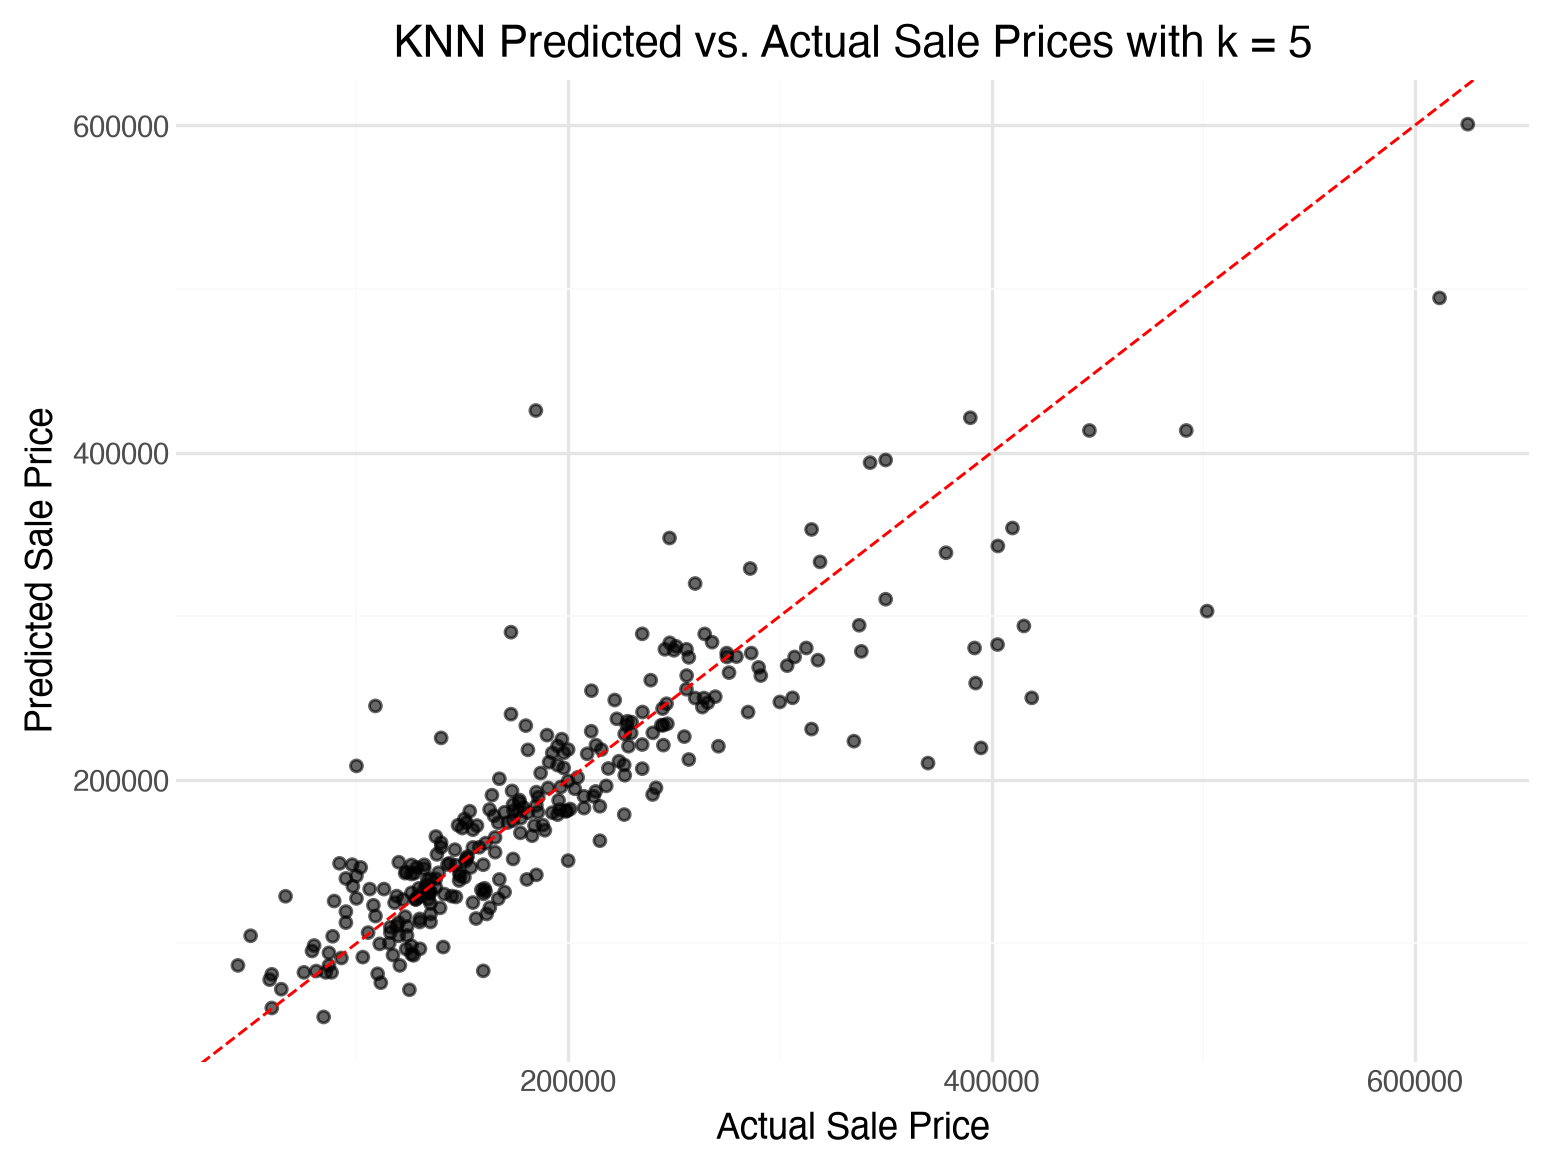

In [22]:
plot_data_knn_5 = pd.DataFrame({
    "actual_price": y_test.to_numpy(),
    "predicted_price": predictions_5
})

(
    ggplot(
        plot_data_knn_5,
        aes(
            x="actual_price",
            y="predicted_price"
        )
    )
    + geom_point(alpha=0.6)
    + labs(
        x="Actual Sale Price",
        y="Predicted Sale Price",
        title="KNN Predicted vs. Actual Sale Prices with k = 5"
    )
    + theme_minimal()
    + geom_abline(
    intercept=0,
    slope=1,
    color="red",
    linetype="dashed"
)
)

In [23]:
print("k = 10:", root_mean_squared_error(y_test, predictions))
print("k = 5:", root_mean_squared_error(y_test, predictions_5))

k = 10: 43844.2207375729
k = 5: 42287.225357628115


Of the two values I tested, k = 5 seemed best because its test RMSE was approximately $42,287, compared with $43,844 for k = 10. The lower RMSE means that k = 5 produced smaller prediction errors overall on this test set.

13. Fit a regression decison tree that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Use a max depth of 4. Use a pipeline and column transformers as needed. Plot and interpret the tree. Also, make a scatter plot of predicting price versus actual price.

In [24]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
target = "SalePrice"

numeric_features = [
    "Gr Liv Area",    # Above-ground living area in square feet
    "Bedroom AbvGr",  # Number of bedrooms above ground
    "Full Bath", 
    "Half Bath"     # Number of full bathrooms
]

categorical_features = [
    "Neighborhood"
]

all_features = numeric_features + categorical_features

data = df_housing[
    [target] + all_features
].copy()

X = data[all_features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.10,  
    random_state=42,  
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features,
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
            categorical_features,
        ),
    ],

    remainder="drop",
)


dt_4 = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("decision_tree",  DecisionTreeRegressor(
            max_depth=4,
            random_state=42
        ),
),
    ]
)

dt_4.fit(X_train, y_train)
predictions_dt_4 = dt_4.predict(X_test)

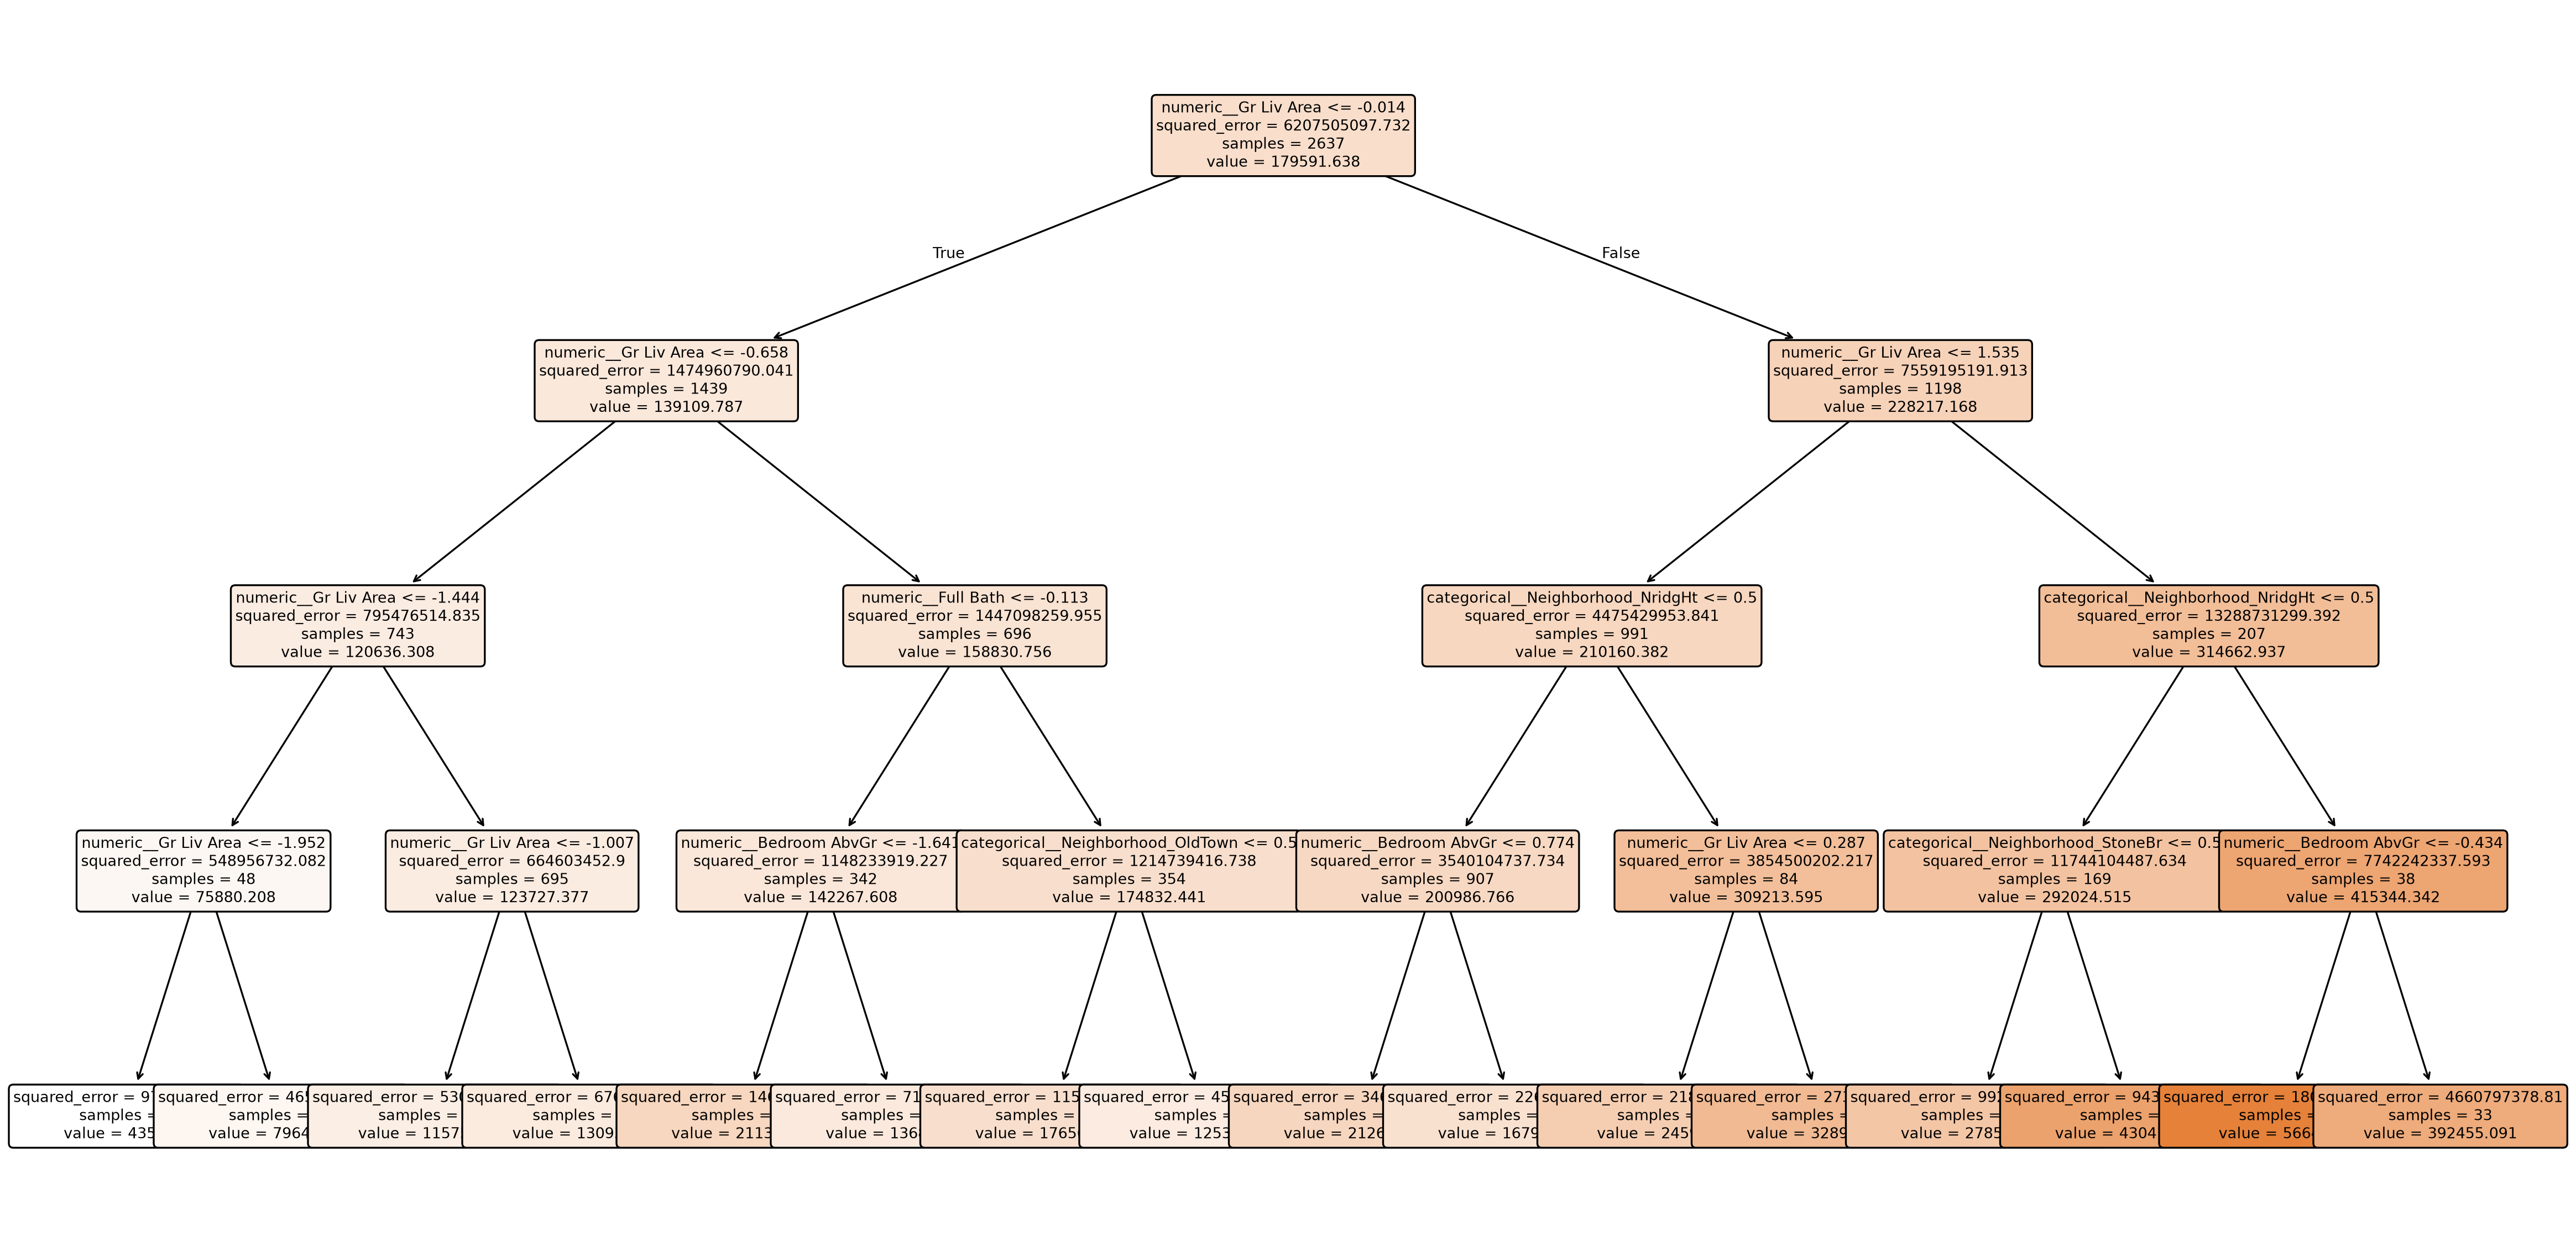

In [25]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

feature_names = (
    dt_4.named_steps["preprocessing"]
    .get_feature_names_out()
)

plt.figure(figsize=(24, 12))

plot_tree(
    dt_4.named_steps["decision_tree"],
    feature_names=feature_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

The decision tree divides houses into groups using predictor cutoffs and predicts the average sale price within each final group. Because the tree is limited to a maximum depth of 4, its predictions appear in a relatively small number of horizontal bands. It captures broad differences between houses but may miss some variation, particularly among more expensive houses.

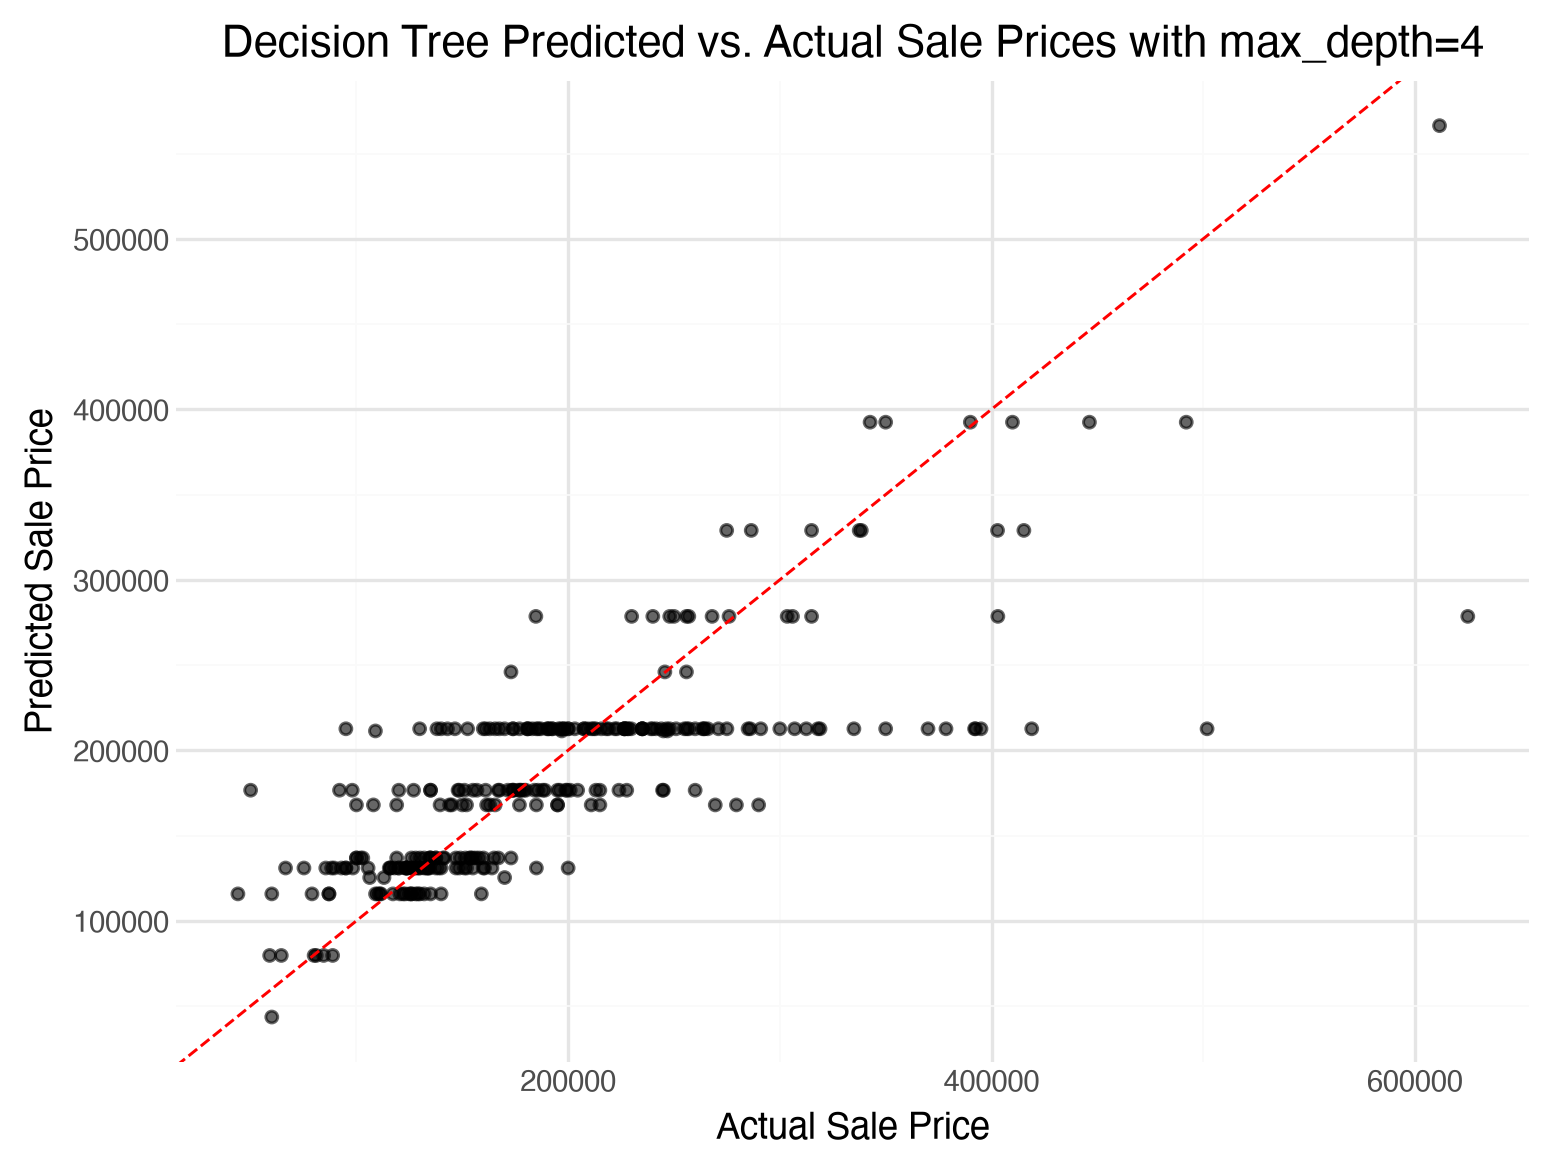

In [26]:
plot_data_dt_4 = pd.DataFrame({
    "actual_price": y_test.to_numpy(),
    "predicted_price": predictions_dt_4
})

(
    ggplot(
        plot_data_dt_4,
        aes(
            x="actual_price",
            y="predicted_price"
        )
    )
    + geom_point(alpha=0.6)
    + labs(
        x="Actual Sale Price",
        y="Predicted Sale Price",
        title="Decision Tree Predicted vs. Actual Sale Prices with max_depth=4"
    )
    + theme_minimal()
    + geom_abline(
    intercept=0,
    slope=1,
    color="red",
    linetype="dashed"
)
)

14. Repeat the previous part with different values of `max_depth`. What value of seems to be "best"? How are you deciding?

In [27]:
# YOUR CODE HERE. ADD CELLS AS NEEDED
target = "SalePrice"

numeric_features = [
    "Gr Liv Area",    # Above-ground living area in square feet
    "Bedroom AbvGr",  # Number of bedrooms above ground
    "Full Bath", 
    "Half Bath"     # Number of full bathrooms
]

categorical_features = [
    "Neighborhood"
]

all_features = numeric_features + categorical_features

data = df_housing[
    [target] + all_features
].copy()

X = data[all_features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.10,  
    random_state=42,  
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features,
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
            categorical_features,
        ),
    ],

    remainder="drop",
)


dt = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("decision_tree",  DecisionTreeRegressor(
            max_depth=20,
            random_state=42
        ),
),
    ]
)

dt.fit(X_train, y_train)
predictions_dt = dt.predict(X_test)

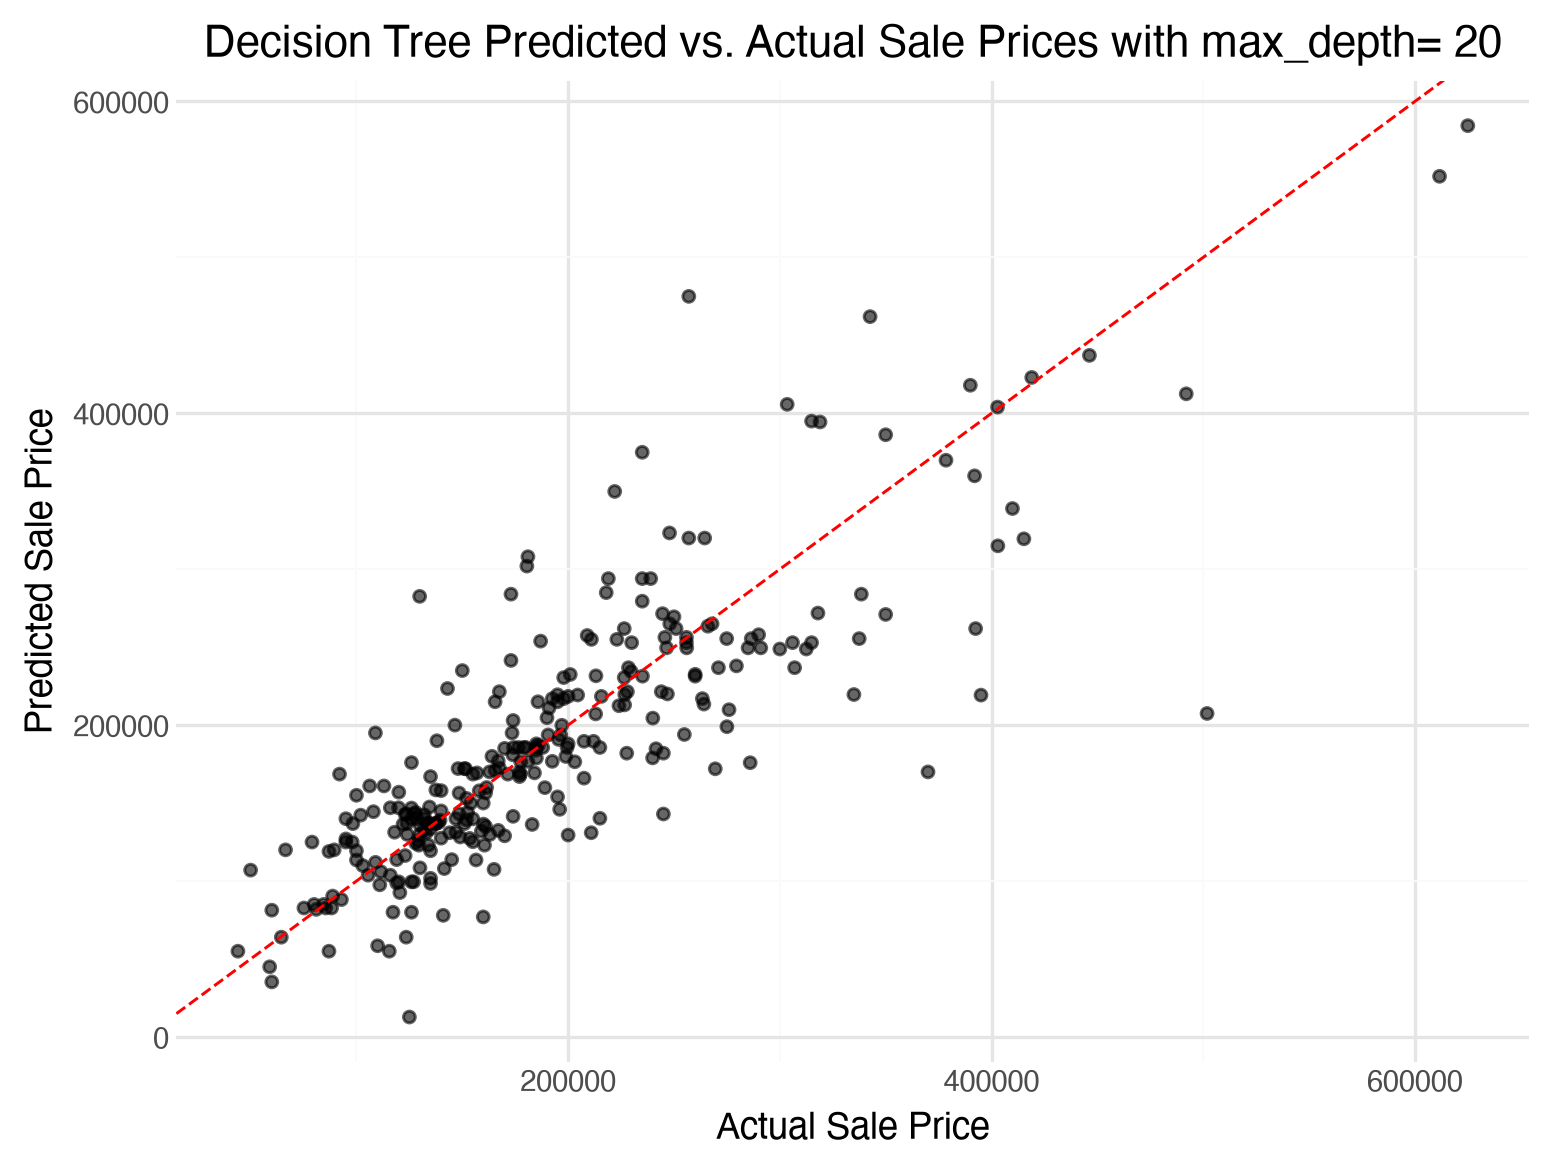

In [28]:
plot_data_dt = pd.DataFrame({
    "actual_price": y_test.to_numpy(),
    "predicted_price": predictions_dt
})

(
    ggplot(
        plot_data_dt,
        aes(
            x="actual_price",
            y="predicted_price"
        )
    )
    + geom_point(alpha=0.6)
    + labs(
        x="Actual Sale Price",
        y="Predicted Sale Price",
        title="Decision Tree Predicted vs. Actual Sale Prices with max_depth= 20"
    )
    + theme_minimal()
    + geom_abline(
    intercept=0,
    slope=1,
    color="red",
    linetype="dashed"
)
)

Among the values I tried, max_depth=20 seemed best because its test-set predictions appeared closest to the red line, where predicted and actual prices are equal. I decided by visually comparing the scatter plots. However, I know that the deeper a tree gets, the greater chance its at the risk of overfitting.